Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
%matplotlib inline

In [6]:
# Load the movies dataset
automobiles_df = pd.read_csv('automobile.txt')

### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [7]:
# Code here
automobiles_df.drop('normalized-losses', axis=1, inplace=True)
automobiles_df.head(10)


,symboling,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,audi,gas,std,four,sedan,fwd,front,99.8,176.6,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,audi,gas,std,four,sedan,4wd,front,99.4,176.6,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
5,2,audi,gas,std,two,sedan,fwd,front,99.8,177.3,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
6,1,audi,gas,std,four,sedan,fwd,front,105.8,192.7,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,17710
7,1,audi,gas,std,four,wagon,fwd,front,105.8,192.7,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,18920
8,1,audi,gas,turbo,four,sedan,fwd,front,105.8,192.7,...,131,mpfi,3.13,3.40,8.3,140,5500,17,20,23875
9,0,audi,gas,turbo,two,hatchback,4wd,front,99.5,178.2,...,131,mpfi,3.13,3.40,7.0,160,5500,16,22,?


In [8]:
automobiles_df.drop('symboling', axis=1, inplace=True)
automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove any duplicate rows

Return the number of rows and columns of the automobiles dataframe

In [9]:
# Return the number of rows and columns of the Automobile DataFrame
automobiles_df.shape

(205, 24)

In [ ]:
# Code here
# Create a temporary automobiles DataFrame
cleaned_df = automobiles_df

# Remove all duplicate rows in the automobiles DataFrame
cleaned_df = automobiles_df.drop_duplicates()
print(cleaned_df)

            make fuel-type aspiration num-of-doors   body-style drive-wheels  \
0    alfa-romero       gas        std          two  convertible          rwd   
1    alfa-romero       gas        std          two  convertible          rwd   
2    alfa-romero       gas        std          two    hatchback          rwd   
3           audi       gas        std         four        sedan          fwd   
4           audi       gas        std         four        sedan          4wd   
..           ...       ...        ...          ...          ...          ...   
200        volvo       gas        std         four        sedan          rwd   
201        volvo       gas      turbo         four        sedan          rwd   
202        volvo       gas        std         four        sedan          rwd   
203        volvo    diesel      turbo         four        sedan          rwd   
204        volvo       gas      turbo         four        sedan          rwd   

    engine-location  wheel-base  length

#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [11]:
# Code here
# Get the number of missing data values per column
missing_values_count = automobiles_df.isnull().sum()

# Look at the number of missing values in the first ten columns
missing_values_count[0:10]

make               0
fuel-type          0
aspiration         0
num-of-doors       0
body-style         0
drive-wheels       0
engine-location    0
wheel-base         0
length             0
width              0
dtype: int64

Removing rows with missing data

In [12]:
# Create a temporary DataFrame
temp_df = automobiles_df

# Remove all the rows that contain a missing value
temp_df.dropna().head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [ ]:
# Code here
# Converting numerical columns to an int64
#colums = ["wheel-base", "length", "width"]
#automobiles_df[colums] = automobiles_df[colums].astype(np.int64)

def convert_columns_int64(df, target_patterns=None, threshold=90):
    """
    Convert matching float/base10 numeric columns to int64 using fuzzy matching

    Args:
        df in this case automobiles_df
        target_patterns : Column name to match against
        threshold: int
            Fuzzy matching threshold (0-100)
    """
    if target_patterns is None:
        target_patterns = [
            "wheel-base",
            "length",
            "width",
            "bore",
            "stroke",
            "compression-ratio"
        ]

    automobiles_df = automobiles_df.copy()

    for col in automobiles_df.columns:

        # Fuzzy match column names
        best_match = max(
            fuzz.partial_ratio(col.lower(), pattern.lower())
            for pattern in target_patterns
        )

        # Check numeric dtype and fuzzy match threshold
        if best_match >= threshold:

            # Convert float column
            if automobiles_df[col].isnull().any():
                automobiles_df[col] = automobiles_df[col].astype("int64")
            else:
                automobiles_df[col] = df[col].astype(np.int64)

        # convert integer columns
        elif pd.api.types.is_integer_dtype(automobiles_df[col]):
            automobiles_df[col] = automobiles_df[col].astype(np.int64)

    return automobiles_df






### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [14]:
# Create a dataframe with all the cars in the "hatchback' category
hatchback_cars = automobiles_df[automobiles_df["body-style"] == "hatchback"]
print(hatchback_cars)


            make fuel-type aspiration num-of-doors body-style drive-wheels  \
2    alfa-romero       gas        std          two  hatchback          rwd   
9           audi       gas      turbo          two  hatchback          4wd   
18     chevrolet       gas        std          two  hatchback          fwd   
19     chevrolet       gas        std          two  hatchback          fwd   
21         dodge       gas        std          two  hatchback          fwd   
..           ...       ...        ...          ...        ...          ...   
175       toyota       gas        std         four  hatchback          fwd   
177       toyota       gas        std         four  hatchback          fwd   
178       toyota       gas        std          two  hatchback          rwd   
179       toyota       gas        std          two  hatchback          rwd   
190   volkswagen       gas        std          two  hatchback          fwd   

    engine-location  wheel-base  length  width  ...  engine-siz

### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [15]:
# Code here

most_expensive_cars = automobiles_df.loc[automobiles_df["price"].idxmax()]
print("The five most expensive cars are: ")
print(most_expensive_cars)

automobiles_df.head()

The five most expensive cars are: 
make                      audi
fuel-type                  gas
aspiration               turbo
num-of-doors               two
body-style           hatchback
drive-wheels               4wd
engine-location          front
wheel-base                99.5
length                   178.2
width                     67.9
height                    52.0
curb-weight               3053
engine-type                ohc
num-of-cylinders          five
engine-size                131
fuel-system               mpfi
bore                      3.13
stroke                    3.40
compression-ratio          7.0
horsepower                 160
peak-rpm                  5500
city-mpg                    16
highway-mpg                 22
price                        ?
Name: 9, dtype: object


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

In [16]:
# Code here

most_efficient_vehicle_city = automobiles_df.loc[automobiles_df["city-mpg"].idxmax()]
print("Most efficient vehicle in the city-mpg is ")
print(most_efficient_vehicle_city)

most_efficient_vehicle_highway = automobiles_df.loc[automobiles_df["highway-mpg"].idxmax()]
print("Most efficient vehicle in highway-mpg is:")
print(most_efficient_vehicle_highway)
automobiles_df.head()


Most efficient vehicle in the city-mpg is 
make                     honda
fuel-type                  gas
aspiration                 std
num-of-doors               two
body-style           hatchback
drive-wheels               fwd
engine-location          front
wheel-base                86.6
length                   144.6
width                     63.9
height                    50.8
curb-weight               1713
engine-type                ohc
num-of-cylinders          four
engine-size                 92
fuel-system               1bbl
bore                      2.91
stroke                    3.41
compression-ratio          9.6
horsepower                  58
peak-rpm                  4800
city-mpg                    49
highway-mpg                 54
price                     6479
Name: 30, dtype: object
Most efficient vehicle in highway-mpg is:
make                     honda
fuel-type                  gas
aspiration                 std
num-of-doors               two
body-style           ha

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


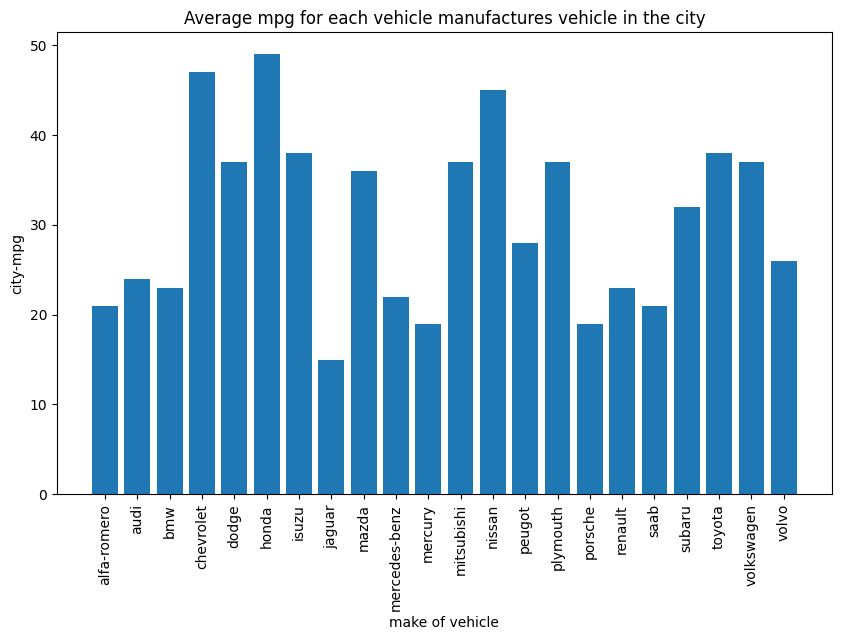

In [21]:
# Create a bar chart
plt.figure(figsize=(10, 6))

plt.bar(automobiles_df["make"], automobiles_df["city-mpg"])

# Labels and title
plt.xlabel("make of vehicle")
plt.ylabel("city-mpg")
plt.title("Average mpg for each vehicle manufactures vehicle in the city")

# Rotate vehicles
plt.xticks(rotation=90)

# Show plot
plt.show()



Average mpg for each vehicle manufacturers in highway

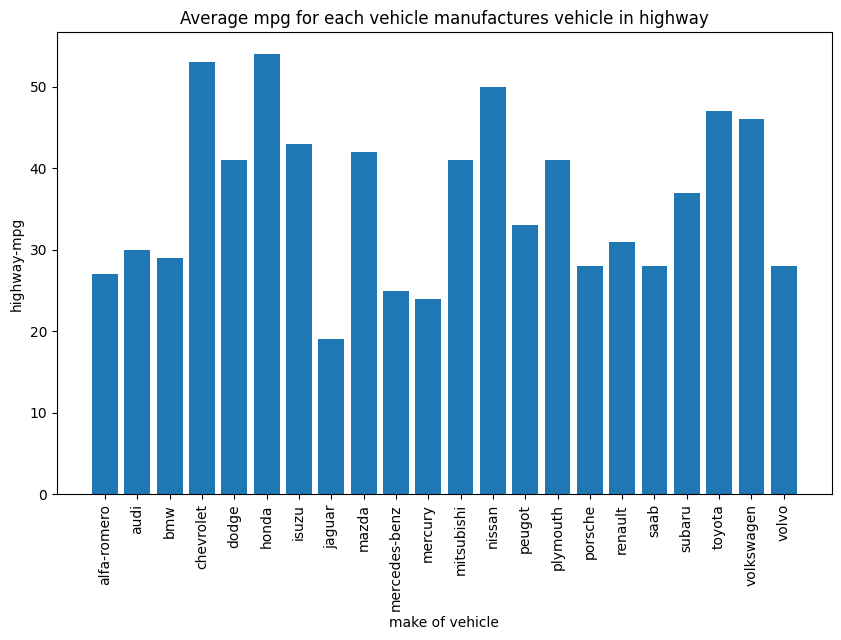

In [22]:
# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(automobiles_df["make"], automobiles_df["highway-mpg"])

# Labels and title
plt.xlabel("make of vehicle")
plt.ylabel("highway-mpg")
plt.title("Average mpg for each vehicle manufactures vehicle in highway")

# Rotate make names
plt.xticks(rotation=90)

# Show plot
plt.show()

#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [17]:
# Code here
automobiles_df.sort_values(by='engine-size', ascending=False).head()


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
49,jaguar,gas,std,two,sedan,rwd,front,102.0,191.7,70.6,...,326,mpfi,3.54,2.76,11.5,262,5000,13,17,36000
73,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,208.1,71.7,...,308,mpfi,3.80,3.35,8.0,184,4500,14,16,40960
74,mercedes-benz,gas,std,two,hardtop,rwd,front,112.0,199.2,72.0,...,304,mpfi,3.80,3.35,8.0,184,4500,14,16,45400
48,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,...,258,mpfi,3.63,4.17,8.1,176,4750,15,19,35550
47,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,...,258,mpfi,3.63,4.17,8.1,176,4750,15,19,32250


#### Which vehicle manufacturer has the most car models in the dataset

In [18]:
# Code here
highest_car_model = automobiles_df.loc[automobiles_df["make"].idxmin()]
print("Manufacturer with the highest model is: ")
print(highest_car_model["make"])



Manufacturer with the highest model is: 
alfa-romero


The report was written by Lungelo Ndabambi